In [ ]:
!pip install git+https://github.com/MSMRo/signalDraw-isb.git

  Cloning https://github.com/MSMRo/signalDraw-isb.git to /tmp/pip-req-build-qs9psnz3
  Running command git clone --filter=blob:none --quiet https://github.com/MSMRo/signalDraw-isb.git /tmp/pip-req-build-qs9psnz3
  Resolved https://github.com/MSMRo/signalDraw-isb.git to commit a414e2773ffe45d332558fefdfbb3b5d5739b89c
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 62.2 MB/s eta 0:00:00
  Created wheel for signaldraw-isb: filename=signaldraw_isb-0.1.0-py3-none-any.whl size=7729 sha256=3ef41898e99f96dc9c2d220a0bbd670ef7f235f45497347820676ba944915ca1
  Stored in directory: /tmp/pip-ephem-wheel-cache-fklic8oz/wheels/a1/6a/b2/5fbb64642172e5c20aeab3e137b6f969bfed7f9c1dafde72b1
Successfully built signaldraw-isb


## **1. Creación de la señal**

In [ ]:
from signaldraw_isb import SignalDraw

ui = SignalDraw()
ui

In [ ]:
fs = ui.fs[0]
x = ui.signals[0]

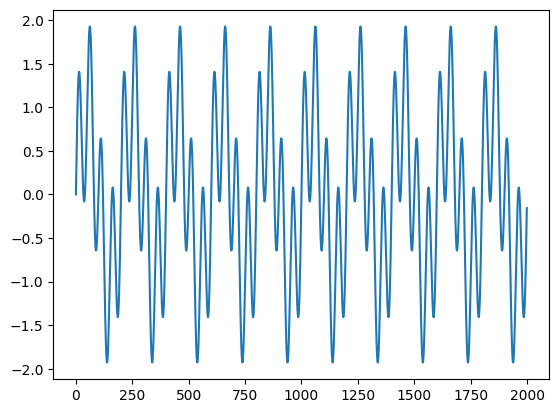

In [ ]:
import matplotlib.pyplot as plt

plt.plot(x)

## 2. **Creación del filtro**

In [ ]:
from scipy.signal import butter, dlti, dbode

b,a = butter(N=5, Wn=12, fs=fs)

In [ ]:
h_d = dlti(b,a, dt=1/fs)
h_d

TransferFunctionDiscrete(
array([6.755952e-08, 3.377976e-07, 6.755952e-07, 6.755952e-07,
       3.377976e-07, 6.755952e-08]),
array([ 1.        , -4.75602306,  9.05358993, -8.62245121,  4.10832302,
       -0.78343651]),
dt: 0.001
)

In [ ]:
w, mag, phase = dbode(h_d)

w=w/(2*np.pi)

(-20.0, 5.0)

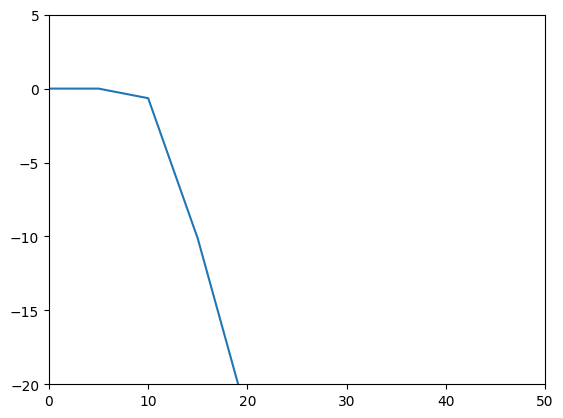

In [ ]:
plt.plot(w, mag)
plt.xlim(0,50)
plt.ylim(-20,5)

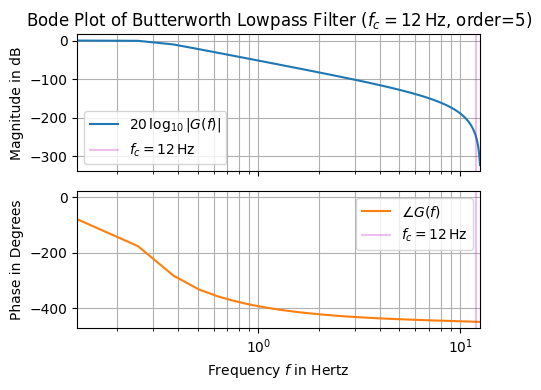

In [ ]:
import numpy as np

f_c = 12
o = 5

w /= 2*np.pi  # convert unit of frequency into Hertz

fg, (ax0, ax1) = plt.subplots(2, 1, sharex='all', figsize=(5, 4),
                              tight_layout=True)
ax0.set_title("Bode Plot of Butterworth Lowpass Filter " +
              rf"($f_c={f_c:g}\,$Hz, order={o})")
ax0.set_ylabel(r"Magnitude in dB")
ax1.set(ylabel=r"Phase in Degrees",
        xlabel="Frequency $f$ in Hertz", xlim=(w[1], w[-1]))
ax0.semilogx(w, mag, 'C0-', label=r"$20\,\log_{10}|G(f)|$")  # Magnitude plot
ax1.semilogx(w, phase, 'C1-', label=r"$\angle G(f)$")  # Phase plot

for ax_ in (ax0, ax1):
    ax_.axvline(f_c, color='m', alpha=0.25, label=rf"${f_c=:g}\,$Hz")
    ax_.grid(which='both', axis='x')  # plot major & minor vertical grid lines
    ax_.grid(which='major', axis='y')
    ax_.legend()
plt.show()

## Uso del filtro

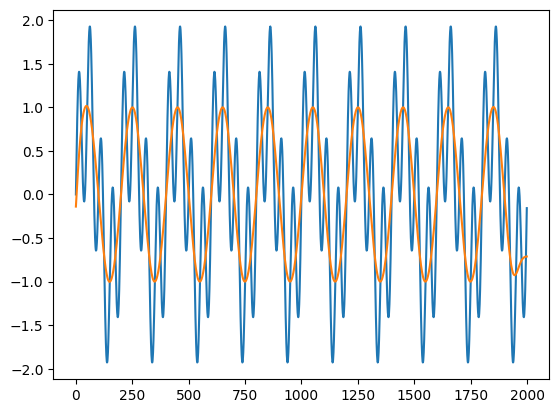

In [ ]:
from scipy.signal import lfilter, filtfilt

y = filtfilt(b,a,x)

plt.plot(x)
plt.plot(y)

(-40.0, 5.0)

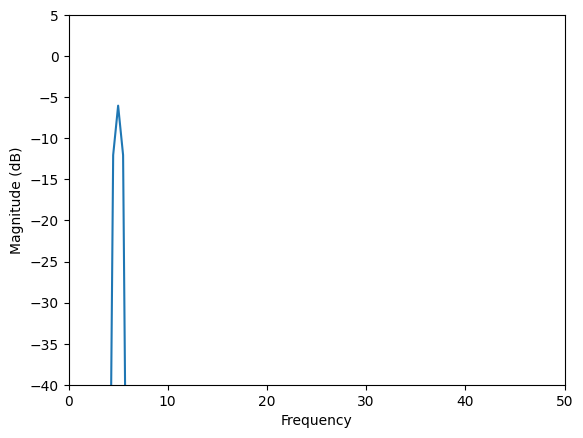

In [ ]:
plt.magnitude_spectrum(y, Fs=fs, scale="dB")
plt.xlim(0,50)
plt.ylim(-40, 5)